# 序列数据准备

在准备 CNN 和 LSTM 的输入之前，先分析训练集的评论长度。

这里暂时使用与前面 TF-IDF 一致的基础分词规则：小写化后提取长度至少为 2 的字母、数字或下划线词项。该统计仅用于探索，序列模型的分词规则尚未最终确定。

In [1]:
# 加载清理后的训练集
import pandas as pd

from sentiment_analysis.paths import CLEANED_DIR

train_data = pd.read_csv(CLEANED_DIR / "train.csv")

print(f"Train: {len(train_data):,}")

Train: 22,413


In [2]:
# 统计每条评论的词项数量
import re

token_pattern = re.compile(r"(?u)\b\w\w+\b")

train_lengths = train_data["text"].apply(
    lambda text: len(token_pattern.findall(text.lower()))
)

display(train_lengths.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(2))

count    22413.00
mean       222.94
std        166.83
min          9.00
50%        166.00
75%        271.00
90%        437.00
95%        573.00
99%        878.88
max       2366.00
Name: text, dtype: float64

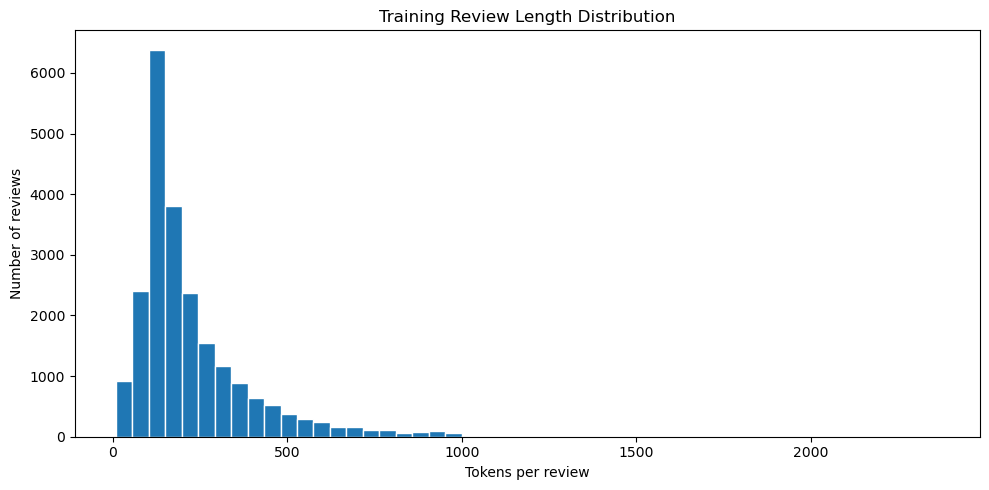

In [3]:
# 绘制训练集评论长度分布
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(train_lengths, bins=50, edgecolor="white")
plt.xlabel("Tokens per review")
plt.ylabel("Number of reviews")
plt.title("Training Review Length Distribution")
plt.tight_layout()
plt.show()

## 候选序列长度

比较不同最大长度下，训练集中有多少评论需要截断。目前仍使用上面的临时分词规则。

In [4]:
# 比较不同最大序列长度对训练集的影响
max_lengths = [128, 256, 384, 512, 768]

rows = []

for max_length in max_lengths:
    truncated_count = (train_lengths > max_length).sum()

    rows.append({
        "MAX LENGTH": max_length,
        "TRUNCATED COUNT": truncated_count,
        "TRUNCATED (%)": truncated_count / len(train_lengths) * 100,
        "FULLY KEPT (%)": (len(train_lengths) - truncated_count) / len(train_lengths) * 100,
    })

length_summary = pd.DataFrame(rows)
display(length_summary.round(2))

,MAX LENGTH,TRUNCATED COUNT,TRUNCATED (%),FULLY KEPT (%)
0,128,15477,69.05,30.95
1,256,6082,27.14,72.86
2,384,2967,13.24,86.76
3,512,1516,6.76,93.24
4,768,415,1.85,98.15


## 探索序列模型的分词规则

前面的规则会忽略 `I` 和 `a` 这样的单字符词，也会拆分部分英文缩写。这里先尝试保留单字符词和词内部的撇号，同时将文本转换为小写。标点不单独作为词项。

In [5]:
# 尝试保留单字符词和英文缩写
sequence_token_pattern = re.compile(r"(?u)\b\w+(?:['’]\w+)*\b")

def tokenize(text: str) -> list[str]:
    return sequence_token_pattern.findall(text.lower())

example_text = "I don't think it's a bad movie!"

print("TF-IDF rule:", token_pattern.findall(example_text.lower()))
print("Sequence rule:", tokenize(example_text))
print("\nTraining review:")
print(train_data.loc[0, "text"][:300])
print("\nFirst 30 tokens:")
print(tokenize(train_data.loc[0, "text"])[:30])

TF-IDF rule: ['don', 'think', 'it', 'bad', 'movie']
Sequence rule: ['i', "don't", 'think', "it's", 'a', 'bad', 'movie']

Training review:
There were some scary scenes, which I've always liked more than straight out gore, but otherwise this movie was rather weak. THere were too many questions left unanswered, and when they tried to explain anything in the movie, it was still rather unclear. After watching this movie I still seemed lost

First 30 tokens:
['there', 'were', 'some', 'scary', 'scenes', 'which', "i've", 'always', 'liked', 'more', 'than', 'straight', 'out', 'gore', 'but', 'otherwise', 'this', 'movie', 'was', 'rather', 'weak', 'there', 'were', 'too', 'many', 'questions', 'left', 'unanswered', 'and', 'when']


In [6]:
# 重新检查评论长度和候选最大长度
sequence_lengths = train_data["text"].apply(lambda text: len(tokenize(text)))

display(sequence_lengths.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(2))

rows = []

for max_length in max_lengths:
    truncated_count = (sequence_lengths > max_length).sum()

    rows.append({
        "MAX LENGTH": max_length,
        "TRUNCATED COUNT": truncated_count,
        "TRUNCATED (%)": truncated_count / len(sequence_lengths) * 100,
        "FULLY KEPT (%)": (len(sequence_lengths) - truncated_count) / len(sequence_lengths) * 100,
    })

sequence_length_summary = pd.DataFrame(rows)
display(sequence_length_summary.round(2))

count    22413.00
mean       233.44
std        173.02
min         10.00
50%        174.00
75%        283.00
90%        456.00
95%        596.00
99%        911.00
max       2473.00
Name: text, dtype: float64

,MAX LENGTH,TRUNCATED COUNT,TRUNCATED (%),FULLY KEPT (%)
0,128,16564,73.90,26.10
1,256,6508,29.04,70.96
2,384,3229,14.41,85.59
3,512,1691,7.54,92.46
4,768,490,2.19,97.81


## 建立训练集词表

暂时采用前面 TF-IDF 的小写化和分词规则，按训练集中的词项总频次选择最多 20,000 个词项。额外设置 `PAD` 和 `UNK`，分别用于填充和表示词表外的词。

这个词表与 TF-IDF 的词表分别构建：这里按总频次排序，不使用 TF-IDF 的 `min_df` 过滤。

In [7]:
# 使用训练集统计词频并建立词表
from collections import Counter

def tfidf_tokenize(text: str) -> list[str]:
    return token_pattern.findall(text.lower())

word_counts = Counter()

for text in train_data["text"]:
    word_counts.update(tfidf_tokenize(text))

max_words = 20_000
sorted_words = sorted(word_counts.items(), key=lambda item: (-item[1], item[0]))

vocabulary = {"<PAD>": 0, "<UNK>": 1}

for word, count in sorted_words[:max_words]:
    vocabulary[word] = len(vocabulary)

print(f"Unique training words: {len(word_counts):,}")
print(f"Selected words: {len(vocabulary) - 2:,}")
print(f"Vocabulary size including PAD and UNK: {len(vocabulary):,}")
print("Most common words:", sorted_words[:10])

Unique training words: 71,671
Selected words: 20,000
Vocabulary size including PAD and UNK: 20,002
Most common words: [('the', 302003), ('and', 146963), ('of', 130616), ('to', 121825), ('is', 96101), ('it', 86644), ('in', 84313), ('this', 68072), ('that', 65804), ('was', 43238)]


In [8]:
# 检查训练集和验证集的词项覆盖情况
validation_data = pd.read_csv(CLEANED_DIR / "val.csv")

splits = {
    "train": train_data,
    "validation": validation_data,
}

rows = []

for name, data in splits.items():
    total_tokens = 0
    unknown_tokens = 0

    for text in data["text"]:
        tokens = tfidf_tokenize(text)
        total_tokens += len(tokens)
        unknown_tokens += sum(token not in vocabulary for token in tokens)

    rows.append({
        "NAME": name,
        "TOKENS": total_tokens,
        "UNKNOWN TOKENS": unknown_tokens,
        "UNKNOWN (%)": unknown_tokens / total_tokens * 100,
    })

vocabulary_summary = pd.DataFrame(rows)
display(vocabulary_summary.round(2))

,NAME,TOKENS,UNKNOWN TOKENS,UNKNOWN (%)
0,train,4996841,120925,2.42
1,validation,563909,15797,2.80


## 文本转换为 Token ID

使用训练集词表将评论转换为数字序列。词表外的词项统一映射为 `<UNK>`；这里先不截断或填充。

In [9]:
# 将评论转换为 Token ID 序列
def encode_text(text: str) -> list[int]:
    tokens = tfidf_tokenize(text)
    return [vocabulary.get(token, vocabulary["<UNK>"]) for token in tokens]

example_text = validation_data.loc[0, "text"]
example_tokens = tfidf_tokenize(example_text)
example_ids = encode_text(example_text)

print(f"Tokens: {len(example_tokens)}")
print(f"Token IDs: {len(example_ids)}")
print(f"Unknown tokens: {example_ids.count(vocabulary['<UNK>'])}")

example_mapping = pd.DataFrame({
    "TOKEN": example_tokens[:30],
    "TOKEN ID": example_ids[:30],
})
display(example_mapping)

Tokens: 239
Token IDs: 239
Unknown tokens: 3


,TOKEN,TOKEN ID
0,king,608
1,solomon,14816
2,mines,8685
3,brings,929
4,us,174
5,patrick,2309
6,swayze,11037
7,playing,382
8,allan,8261
9,quatermain,18667


In [10]:
# 检查示例评论中被映射为 UNK 的词项
unknown_words = [token for token in example_tokens if token not in vocabulary]

print("Unknown words:", unknown_words)
print("UNK ID:", vocabulary["<UNK>"])

Unknown words: ['deedy', 'ruggedly', 'clench']
UNK ID: 1


## 截断与填充

暂定最大长度为 512：长评论保留前 512 个词项，短评论在末尾填充 `<PAD>`。同时记录截断后、填充前的实际长度，供后续序列模型使用。

In [11]:
# 将评论转换为固定长度序列
max_length = 512

def prepare_sequence(text: str, max_length: int) -> tuple[list[int], int]:
    token_ids = encode_text(text)[:max_length]
    sequence_length = len(token_ids)
    token_ids += [vocabulary["<PAD>"]] * (max_length - sequence_length)

    return token_ids, sequence_length

short_index = train_lengths[train_lengths < max_length].index[0]
long_index = train_lengths[train_lengths > max_length].index[0]

for name, index in [("Short review", short_index), ("Long review", long_index)]:
    text = train_data.loc[index, "text"]
    token_ids, sequence_length = prepare_sequence(text, max_length)

    print(f"{name} (index {index}):")
    print(f"Original length: {len(encode_text(text))}")
    print(f"Retained length: {sequence_length}")
    print(f"Padded length: {len(token_ids)}")
    print(f"Padding tokens: {len(token_ids) - sequence_length}")
    print(f"First 10 IDs: {token_ids[:10]}")
    print(f"Last 10 IDs: {token_ids[-10:]}\n")

Short review (index 0):
Original length: 138
Retained length: 138
Padded length: 512
Padding tokens: 374
First 10 IDs: [36, 66, 45, 627, 133, 58, 134, 205, 415, 48]
Last 10 IDs: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Long review (index 25):
Original length: 536
Retained length: 512
Padded length: 512
Padding tokens: 0
First 10 IDs: [372, 781, 14877, 2, 1923, 4, 2992, 14915, 5, 25]
Last 10 IDs: [851, 3, 2, 436, 2267, 4, 2, 17, 11, 40]



## Dataset 与 DataLoader

将每条评论转换为 Token ID 序列、有效长度和标签，再按批次提供给模型。训练集打乱顺序，验证集保持原顺序。

In [12]:
# 定义评论数据集
import torch
from torch.utils.data import Dataset, DataLoader

class SentimentDataset(Dataset):
    def __init__(self, data: pd.DataFrame, max_length: int):
        self.texts = data["text"].reset_index(drop=True)
        self.labels = data["label"].reset_index(drop=True)
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        token_ids, sequence_length = prepare_sequence(self.texts.iloc[index], self.max_length)
        label = self.labels.iloc[index]

        return (
            torch.tensor(token_ids, dtype=torch.long),
            torch.tensor(sequence_length, dtype=torch.long),
            torch.tensor(label, dtype=torch.long),
        )

In [13]:
# 创建训练集和验证集的 DataLoader
train_dataset = SentimentDataset(train_data, max_length)
validation_dataset = SentimentDataset(validation_data, max_length)

batch_size = 32
generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, generator=generator,
)
validation_loader = DataLoader(
    validation_dataset, batch_size=batch_size, shuffle=False,
)

print(f"Train samples: {len(train_dataset):,}")
print(f"Validation samples: {len(validation_dataset):,}")
print(f"Train batches: {len(train_loader):,}")
print(f"Validation batches: {len(validation_loader):,}")

Train samples: 22,413
Validation samples: 2,491
Train batches: 701
Validation batches: 78


In [14]:
# 检查一个训练批次
batch_token_ids, batch_lengths, batch_labels = next(iter(train_loader))

print("Token IDs shape:", batch_token_ids.shape)
print("Lengths shape:", batch_lengths.shape)
print("Labels shape:", batch_labels.shape)
print("First five lengths:", batch_lengths[:5])
print("First five labels:", batch_labels[:5])

# 重置训练集打乱顺序的随机数生成器
generator.manual_seed(42)

Token IDs shape: torch.Size([32, 512])
Lengths shape: torch.Size([32])
Labels shape: torch.Size([32])
First five lengths: tensor([486, 109, 141, 512, 118])
First five labels: tensor([1, 1, 1, 1, 0])


## 观察 Embedding 层

Embedding 根据 Token ID 查找对应的向量。这里使用随机初始化的示例层，只检查输入、输出形状和填充位置；向量尚未经过训练。

In [15]:
# 将一个批次的 Token ID 转换为词向量
from torch import nn

embedding_dim = 128

with torch.random.fork_rng():
    torch.manual_seed(42)
    embedding = nn.Embedding(
        num_embeddings=len(vocabulary),
        embedding_dim=embedding_dim,
        padding_idx=vocabulary["<PAD>"],
    )

with torch.no_grad():
    batch_embeddings = embedding(batch_token_ids)

print("Token IDs shape:", batch_token_ids.shape)
print("Embedding output shape:", batch_embeddings.shape)
print("PAD vector is zero:", torch.all(embedding.weight[vocabulary["<PAD>"]] == 0).item())
print("First token ID:", batch_token_ids[0, 0].item())
print("First five embedding values:", batch_embeddings[0, 0, :5])

Token IDs shape: torch.Size([32, 512])
Embedding output shape: torch.Size([32, 512, 128])
PAD vector is zero: True
First token ID: 17
First five embedding values: tensor([-1.4336, -0.8756,  0.0094,  0.6304,  0.8633])


## 观察卷积与池化

先用一个宽度为 3 的卷积核观察局部词项，再用最大池化汇总整条评论。示例层仍是随机初始化的，尚未训练。

池化时排除完全由填充组成的窗口；评论末尾同时包含真实词项和填充的窗口仍参与计算。

In [16]:
# 观察卷积和池化前后的数据形状
num_filters = 64
kernel_size = 3

with torch.random.fork_rng():
    torch.manual_seed(42)
    convolution = nn.Conv1d(
        in_channels=embedding_dim,
        out_channels=num_filters,
        kernel_size=kernel_size,
    )

with torch.no_grad():
    # Conv1d 接收 [批次, 通道, 序列长度]
    convolution_input = batch_embeddings.transpose(1, 2)
    convolution_output = torch.relu(convolution(convolution_input))

    # 排除完全由 PAD 组成的卷积窗口
    positions = torch.arange(convolution_output.shape[2])
    valid_windows = positions.unsqueeze(0) < batch_lengths.unsqueeze(1)
    masked_output = convolution_output.masked_fill(~valid_windows.unsqueeze(1), float("-inf"))
    pooled_output = masked_output.max(dim=2).values

print("Embedding output shape:", batch_embeddings.shape)
print("Conv1d input shape:", convolution_input.shape)
print("Conv1d output shape:", convolution_output.shape)
print("Pooled output shape:", pooled_output.shape)

Embedding output shape: torch.Size([32, 512, 128])
Conv1d input shape: torch.Size([32, 128, 512])
Conv1d output shape: torch.Size([32, 64, 510])
Pooled output shape: torch.Size([32, 64])


## 观察分类层

分类层将每条评论的池化特征转换为两个类别分数，分别对应负面和正面。示例参数仍是随机初始化的，输出不代表模型的实际分类能力。

In [17]:
# 将池化特征转换为类别分数
with torch.random.fork_rng():
    torch.manual_seed(42)
    classifier = nn.Linear(num_filters, 2)

with torch.no_grad():
    logits = classifier(pooled_output)
    probabilities = torch.softmax(logits, dim=1)
    predictions = logits.argmax(dim=1)

print("Pooled output shape:", pooled_output.shape)
print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)
print("First review logits:", logits[0])
print("First review probabilities:", probabilities[0])
print("First review prediction:", predictions[0].item())
print("First review label:", batch_labels[0].item())

Pooled output shape: torch.Size([32, 64])
Logits shape: torch.Size([32, 2])
Probabilities shape: torch.Size([32, 2])
First review logits: tensor([ 1.0440, -2.7260])
First review probabilities: tensor([0.9775, 0.0225])
First review prediction: 0
First review label: 1


## 组合 TextCNN

将 Embedding、卷积、池化和分类层组合成模型，先检查一个批次的前向计算。池化时继续排除完全由填充组成的窗口。

In [18]:
# 定义基础 TextCNN 模型
class TextCNN(nn.Module):
    def __init__(self, vocabulary_size: int, embedding_dim: int, num_filters: int,
                 kernel_size: int, padding_index: int, dropout: float = 0.5):
        super().__init__()

        self.embedding = nn.Embedding(vocabulary_size, embedding_dim, padding_idx=padding_index)
        self.convolution = nn.Conv1d(embedding_dim, num_filters, kernel_size)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters, 2)

    def forward(self, token_ids, lengths):
        if (lengths <= 0).any():
            raise ValueError("Each sequence must contain at least one token.")

        embeddings = self.embedding(token_ids)
        convolution_input = embeddings.transpose(1, 2)
        convolution_output = torch.relu(self.convolution(convolution_input))

        positions = torch.arange(convolution_output.shape[2], device=token_ids.device)
        valid_windows = positions.unsqueeze(0) < lengths.to(token_ids.device).unsqueeze(1)
        masked_output = convolution_output.masked_fill(~valid_windows.unsqueeze(1), float("-inf"))
        pooled_output = masked_output.max(dim=2).values

        return self.classifier(self.dropout(pooled_output))

In [19]:
# 检查模型输出和一个批次的损失
with torch.random.fork_rng():
    torch.manual_seed(42)
    textcnn_model = TextCNN(
        vocabulary_size=len(vocabulary),
        embedding_dim=embedding_dim,
        num_filters=num_filters,
        kernel_size=kernel_size,
        padding_index=vocabulary["<PAD>"],
    )

loss_function = nn.CrossEntropyLoss()
textcnn_model.eval()

with torch.no_grad():
    batch_logits = textcnn_model(batch_token_ids, batch_lengths)
    batch_loss = loss_function(batch_logits, batch_labels)

print("Output shape:", batch_logits.shape)
print(f"Batch loss: {batch_loss.item():.4f}")

Output shape: torch.Size([32, 2])
Batch loss: 1.0040
